# Retail Orders Data Analysis Using Python

## Project Overview

The objective of this project is to perform Exploratory Data Analysis (EDA) on a retail orders dataset using Python. The project focuses on understanding sales performance, customer segments, product categories, order statuses, payment methods, and monthly sales and profit trends.

The analysis includes data inspection, data cleaning, handling missing values and duplicate records, outlier detection, univariate analysis, bivariate analysis, and time-series analysis. Libraries such as Pandas, NumPy, Matplotlib, and Seaborn are used to process, analyze, and visualize the data.

The main goal is to identify meaningful business insights that can help understand retail performance and support better business decisions.

In [63]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [64]:
df=pd.read_csv("retail_orders_eda_practice.csv")
df.head()

,Order_ID,Order_Date,Customer_ID,Region,City,Customer_Segment,Sales_Channel,Product_Category,Product_Name,Unit_Price,Quantity,Discount,Payment_Method,Order_Status,Shipping_Days,Gross_Sales,Discount_Amount,Net_Sales,Estimated_Cost,Profit
0,ORD-00047,2025-06-16,CUST-0199,East,Patna,Corporate,Phone Order,Electronics,Keyboard,5974.41,1,0.20,Credit Card,Delivered,3.0,5974.41,1194.88,4779.53,3021.95,1757.58
1,ORD-00291,2025-12-15,CUST-0089,East,Patna,Consumer,Retail Store,Office Supplies,Pen Set,475.48,2,0.00,UPI,Delivered,5.0,950.96,0.00,950.96,632.00,318.96
2,ORD-00755,2025-03-19,CUST-0301,East,Bhubaneswar,Corporate,Marketplace,Home & Kitchen,Coffee Maker,4432.65,1,0.25,Credit Card,Processing,7.0,4432.65,1108.16,3324.49,2941.65,382.84
3,ORD-00449,2025-10-17,CUST-0136,North,Lucknow,Consumer,Marketplace,Office Supplies,Notebook,384.28,1,0.30,Net Banking,delivered,4.0,384.28,115.28,269.00,288.06,-19.06
4,ORD-00912,2025-03-27,CUST-0216,North,Chandigarh,Consumer,Marketplace,Electronics,USB Hub,8008.88,5,0.00,UPI,Cancelled,5.0,40044.40,0.00,40044.40,23663.30,16381.10


In [65]:
df.shape

(1212, 20)

In [66]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1212 entries, 0 to 1211
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          1212 non-null   object 
 1   Order_Date        1212 non-null   object 
 2   Customer_ID       1212 non-null   object 
 3   Region            1212 non-null   object 
 4   City              1168 non-null   object 
 5   Customer_Segment  1182 non-null   object 
 6   Sales_Channel     1212 non-null   object 
 7   Product_Category  1212 non-null   object 
 8   Product_Name      1212 non-null   object 
 9   Unit_Price        1198 non-null   float64
 10  Quantity          1212 non-null   int64  
 11  Discount          1212 non-null   float64
 12  Payment_Method    1188 non-null   object 
 13  Order_Status      1212 non-null   object 
 14  Shipping_Days     1164 non-null   float64
 15  Gross_Sales       1212 non-null   float64
 16  Discount_Amount   1212 non-null   float64


In [67]:
df.columns=df.columns.str.strip()

In [68]:
df.duplicated().sum()

np.int64(12)

In [69]:
df.drop_duplicates(inplace=True)

In [70]:
df.duplicated().sum()

np.int64(0)

In [71]:
df["Order_Date"]=pd.to_datetime(df["Order_Date"])

In [72]:
df.isnull().sum()

Order_ID             0
Order_Date           0
Customer_ID          0
Region               0
City                42
Customer_Segment    30
Sales_Channel        0
Product_Category     0
Product_Name         0
Unit_Price          14
Quantity             0
Discount             0
Payment_Method      24
Order_Status         0
Shipping_Days       48
Gross_Sales          0
Discount_Amount      0
Net_Sales            0
Estimated_Cost       0
Profit               0
dtype: int64

In [73]:
missing_value_cols=[col for col in df.columns if df[col].isnull().sum()>0]
missing_value_cols

['City', 'Customer_Segment', 'Unit_Price', 'Payment_Method', 'Shipping_Days']

In [74]:
new=df[['City', 'Customer_Segment', 'Unit_Price', 'Payment_Method', 'Shipping_Days']]
new.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1200 entries, 0 to 1211
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   City              1158 non-null   object 
 1   Customer_Segment  1170 non-null   object 
 2   Unit_Price        1186 non-null   float64
 3   Payment_Method    1176 non-null   object 
 4   Shipping_Days     1152 non-null   float64
dtypes: float64(2), object(3)
memory usage: 56.2+ KB


In [75]:
for col in new.columns:
    print("----")
    print(df[col].value_counts())
    print("")

----
City
Jaipur         100
Lucknow         94
Chandigarh      83
Bhubaneswar     79
Bengaluru       77
Mumbai          76
Ahmedabad       74
Delhi           73
Surat           71
Kolkata         69
Ranchi          66
Hyderabad       63
Kochi           63
Pune            59
Patna           56
Chennai         55
Name: count, dtype: int64

----
Customer_Segment
Consumer          681
Corporate         321
Small Business    168
Name: count, dtype: int64

----
Unit_Price
5579.81     1
5974.41     1
3864.70     1
19191.87    1
7075.36     1
           ..
15363.31    1
471.86      1
8008.88     1
384.28      1
4432.65     1
Name: count, Length: 1186, dtype: int64

----
Payment_Method
UPI             415
Credit Card     256
Debit Card      237
Cash            152
Net Banking     104
credit card       6
Net banking       6
Name: count, dtype: int64

----
Shipping_Days
3.0     261
4.0     204
5.0     176
2.0     175
1.0      87
6.0      86
7.0      66
8.0      52
10.0     31
14.0     13
75.0   

In [76]:
df=df.apply(lambda col:col.str.strip() if col.dtype=="object" else col)
df.head(2)

,Order_ID,Order_Date,Customer_ID,Region,City,Customer_Segment,Sales_Channel,Product_Category,Product_Name,Unit_Price,Quantity,Discount,Payment_Method,Order_Status,Shipping_Days,Gross_Sales,Discount_Amount,Net_Sales,Estimated_Cost,Profit
0,ORD-00047,2025-06-16,CUST-0199,East,Patna,Corporate,Phone Order,Electronics,Keyboard,5974.41,1,0.2,Credit Card,Delivered,3.0,5974.41,1194.88,4779.53,3021.95,1757.58
1,ORD-00291,2025-12-15,CUST-0089,East,Patna,Consumer,Retail Store,Office Supplies,Pen Set,475.48,2,0.0,UPI,Delivered,5.0,950.96,0.00,950.96,632.00,318.96


In [77]:
df.columns

Index(['Order_ID', 'Order_Date', 'Customer_ID', 'Region', 'City',
       'Customer_Segment', 'Sales_Channel', 'Product_Category', 'Product_Name',
       'Unit_Price', 'Quantity', 'Discount', 'Payment_Method', 'Order_Status',
       'Shipping_Days', 'Gross_Sales', 'Discount_Amount', 'Net_Sales',
       'Estimated_Cost', 'Profit'],
      dtype='object')

In [78]:
cols=['Region','Sales_Channel','Order_Status','Product_Category','Payment_Method']

# Remove leading/trailing spaces and standardize capitalization
df[cols]=df[cols].apply(lambda col:col.str.title())

In [79]:
for col in cols:
    print(df[col].value_counts())
    print("------")

Region
North    360
West     297
East     277
South    266
Name: count, dtype: int64
------
Sales_Channel
Online          499
Marketplace     318
Retail Store    287
Phone Order      96
Name: count, dtype: int64
------
Order_Status
Delivered     789
Shipped       179
Processing    101
Cancelled      73
Returned       58
Name: count, dtype: int64
------
Product_Category
Office Supplies    271
Electronics        263
Clothing           238
Furniture          220
Home & Kitchen     208
Name: count, dtype: int64
------
Payment_Method
Upi            415
Credit Card    262
Debit Card     237
Cash           152
Net Banking    110
Name: count, dtype: int64
------


In [80]:
missing=pd.DataFrame((df.isnull().sum()*100)/len(df))
missing

,0
Order_ID,0.000000
Order_Date,0.000000
Customer_ID,0.000000
Region,0.000000
City,3.500000
Customer_Segment,2.500000
Sales_Channel,0.000000
Product_Category,0.000000
Product_Name,0.000000
Unit_Price,1.166667


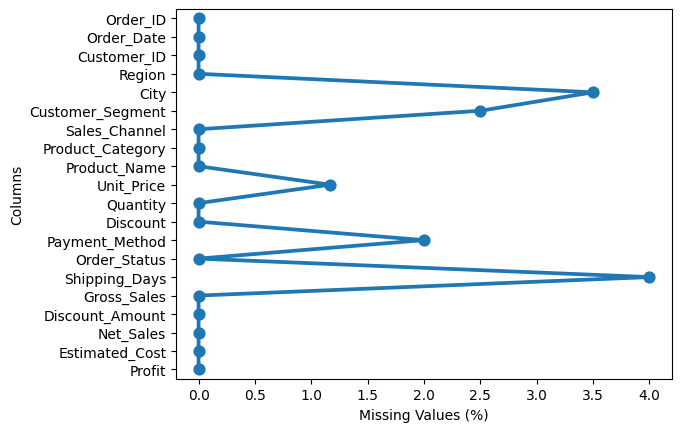

In [81]:
sns.pointplot(x=missing[0],y=missing.index)
plt.xlabel("Missing Values (%)")
plt.ylabel("Columns")
plt.show()

In [82]:
new.select_dtypes(include="object").columns

Index(['City', 'Customer_Segment', 'Payment_Method'], dtype='object')

In [83]:
obj_cols=['City', 'Customer_Segment', 'Payment_Method']
for col in obj_cols:
    df[col]=df[col].fillna(df[col].mode()[0])

In [84]:
new.select_dtypes(include="number").columns

Index(['Unit_Price', 'Shipping_Days'], dtype='object')

In [85]:
numerical_cols=['Unit_Price', 'Shipping_Days']
for col in numerical_cols:
    df[col]=df[col].fillna(df[col].median())

In [86]:
df.isnull().sum()

Order_ID            0
Order_Date          0
Customer_ID         0
Region              0
City                0
Customer_Segment    0
Sales_Channel       0
Product_Category    0
Product_Name        0
Unit_Price          0
Quantity            0
Discount            0
Payment_Method      0
Order_Status        0
Shipping_Days       0
Gross_Sales         0
Discount_Amount     0
Net_Sales           0
Estimated_Cost      0
Profit              0
dtype: int64

In [87]:
df.describe()

,Order_Date,Unit_Price,Quantity,Discount,Shipping_Days,Gross_Sales,Discount_Amount,Net_Sales,Estimated_Cost,Profit
count,1200,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,2025-07-02 13:28:48,5267.054833,2.946667,0.109708,4.224167,15409.529908,1661.718533,13747.811375,9670.288942,4077.522433
min,2025-01-01 00:00:00,40.970000,-2.000000,-0.100000,1.000000,40.970000,0.000000,40.970000,22.300000,-6576.630000
25%,2025-04-08 18:00:00,809.140000,1.000000,0.050000,3.000000,1864.887500,16.382500,1665.272500,1187.292500,365.077500
50%,2025-06-29 00:00:00,2787.575000,2.000000,0.100000,4.000000,6278.910000,338.985000,5660.215000,4013.840000,1464.545000
75%,2025-10-01 06:00:00,8041.117500,4.000000,0.150000,5.000000,17798.250000,1625.665000,15880.915000,11217.160000,4531.585000
max,2025-12-31 00:00:00,21926.170000,10.000000,1.200000,75.000000,175409.360000,46965.310000,175409.360000,116162.360000,84352.690000
std,NaN,5792.682947,2.190393,0.092299,3.040826,23852.009000,3485.206365,21586.836121,15132.643780,7456.135163


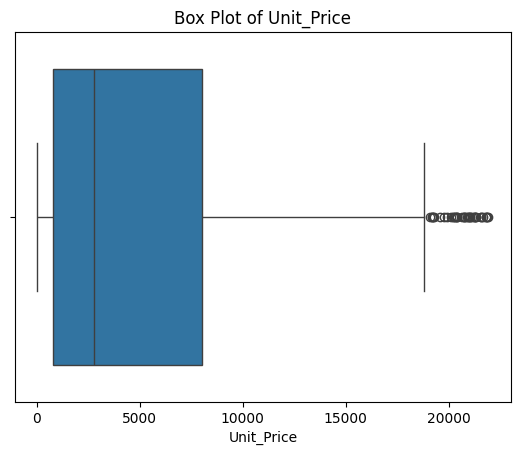

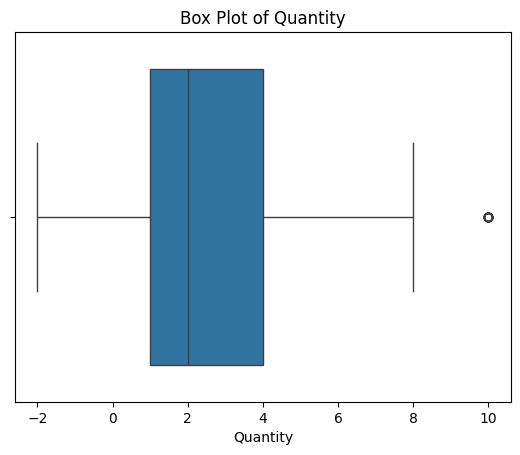

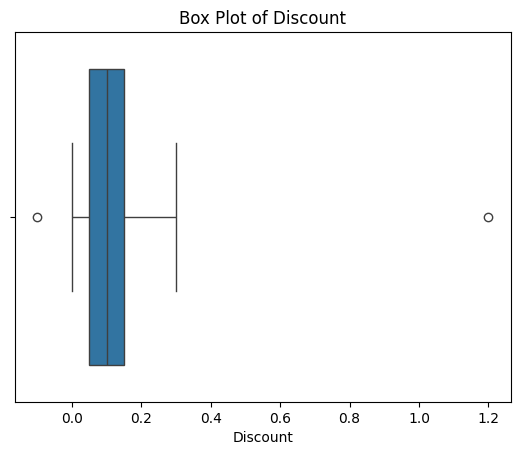

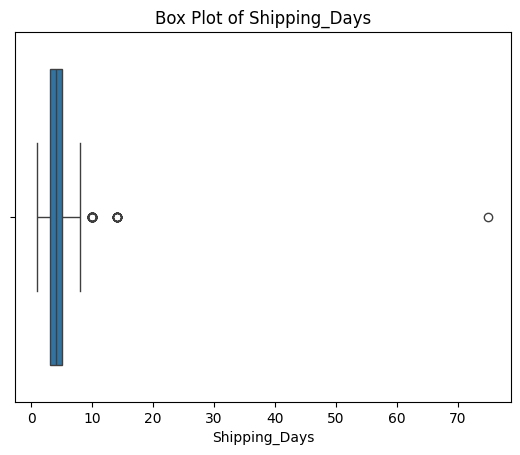

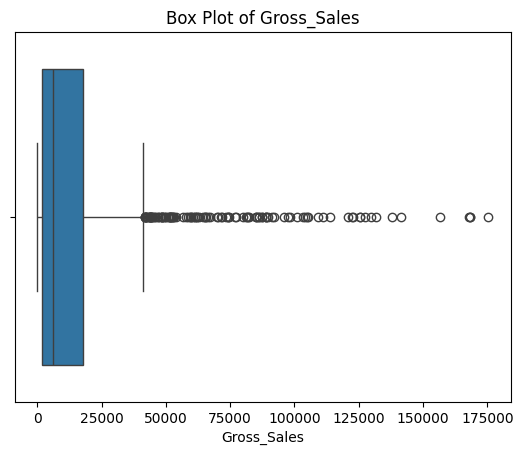

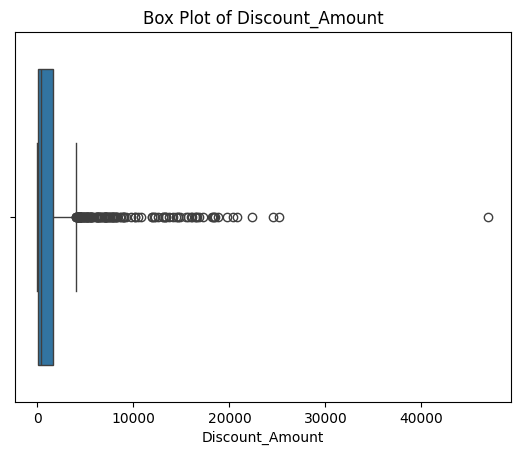

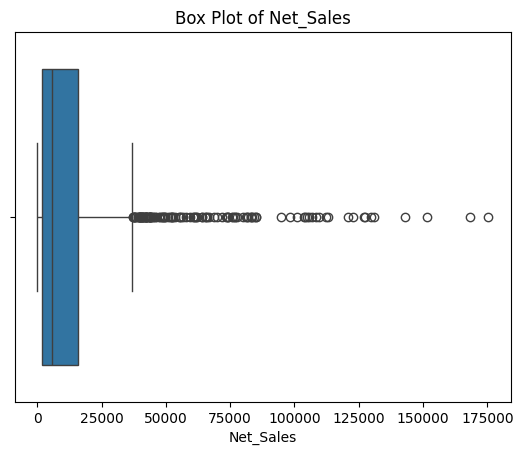

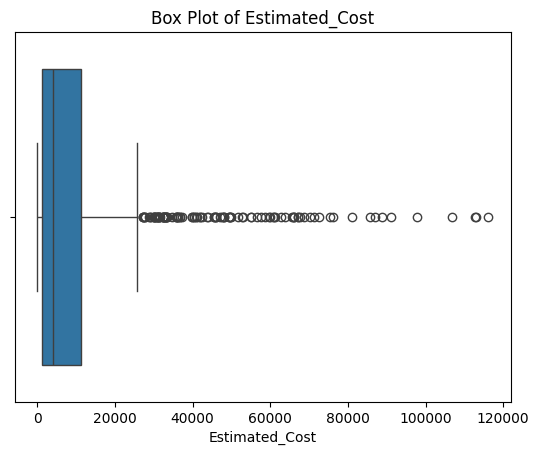

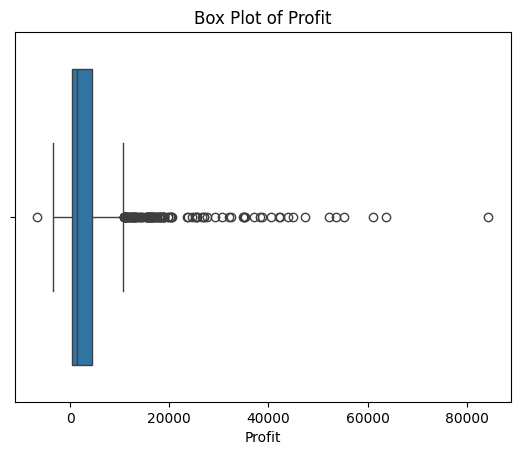

In [88]:
cols=["Unit_Price","Quantity","Discount","Shipping_Days","Gross_Sales","Discount_Amount","Net_Sales","Estimated_Cost","Profit"]
for col in cols:
    sns.boxplot(x=df[col])
    plt.title(f"Box Plot of {col}")
    plt.show()

In [89]:
cols=["Unit_Price","Quantity","Discount","Shipping_Days","Gross_Sales","Discount_Amount","Net_Sales","Estimated_Cost","Profit"]
for col in cols:
    q1=np.quantile(df[col],0.25)
    q3=np.quantile(df[col],0.75)
    iqr=q3-q1
    mini=q1-1.5*iqr
    maxi=q3+1.5*iqr

    outliers=df[(df[col]<mini) | (df[col]>maxi)]
    print(f"{col}:{len(outliers)} outliers")

Unit_Price:36 outliers
Quantity:30 outliers
Discount:2 outliers
Shipping_Days:45 outliers
Gross_Sales:114 outliers
Discount_Amount:141 outliers
Net_Sales:120 outliers
Estimated_Cost:110 outliers
Profit:114 outliers


In [90]:
cols=["Unit_Price","Quantity","Discount","Shipping_Days","Gross_Sales","Discount_Amount","Net_Sales","Estimated_Cost","Profit"]
for col in cols:
    q1=np.quantile(df[col],0.25)
    q3=np.quantile(df[col],0.75)
    iqr=q3-q1
    mini=q1-1.5*iqr
    maxi=q3+1.5*iqr

    outliers=df[(df[col]<mini) | (df[col]>maxi)]
    print(f"{col}:{len(outliers)} outliers")

Unit_Price:36 outliers
Quantity:30 outliers
Discount:2 outliers
Shipping_Days:45 outliers
Gross_Sales:114 outliers
Discount_Amount:141 outliers
Net_Sales:120 outliers
Estimated_Cost:110 outliers
Profit:114 outliers


In [91]:
cols=["Unit_Price","Quantity","Discount","Shipping_Days","Gross_Sales","Discount_Amount","Net_Sales","Estimated_Cost","Profit"]
for col in cols:
    q1=np.quantile(df[col],0.25)
    q3=np.quantile(df[col],0.75)
    iqr=q3-q1
    mini=q1-1.5*iqr
    maxi=q3+1.5*iqr

    outliers=df[(df[col]<mini) | (df[col]>maxi)]
    print(f"{col}:{len(outliers)} outliers")

Unit_Price:36 outliers
Quantity:30 outliers
Discount:2 outliers
Shipping_Days:45 outliers
Gross_Sales:114 outliers
Discount_Amount:141 outliers
Net_Sales:120 outliers
Estimated_Cost:110 outliers
Profit:114 outliers


In [92]:
#1. Check Unit_Price
print("Negative or Zero Unit Price: ")
print(df[df["Unit_Price"]<=0]["Unit_Price"])
print("-"*50)

#2. Check Quantity
print("Negative or Zero Quantity:")
print(df[df["Quantity"]<=0]["Quantity"])
print("-"*50)

#3. Check Discount
print("Negative or Zero Discount:")
print(df[(df["Discount"]<0) & (df["Discount"]>1)]["Discount"])
print("-"*50)

#4. Check Shipping Days
print("Negative Shipping_Days:")
print(df[df["Shipping_Days"]<0]["Shipping_Days"])
print("-"*50)

#5. Check Gross_Sales
print("Negative Gross_Sales:")
print(df[df["Gross_Sales"]<0]["Gross_Sales"])
print("-"*50)

#6. Check Discount_Amount
print("Negative Discount_Amount:")
print(df[df["Discount_Amount"]<0]["Discount_Amount"])
print("-"*50)

#7. Check Net_Sales
print("Negative Net_Sales:")
print(df[df["Net_Sales"]<0]["Net_Sales"])
print("-"*50)

#8. Check Estimated_Cost
print("Negative Estimated_Cost:")
print(df[df["Estimated_Cost"]<0]["Estimated_Cost"])
print("-"*50)

#9. Check Profit
print("Negative Profit:")
print(df[df["Profit"]<0]["Profit"])
print("-"*50)

Negative or Zero Unit Price: 
Series([], Name: Unit_Price, dtype: float64)
--------------------------------------------------
Negative or Zero Quantity:
270    0
908   -2
Name: Quantity, dtype: int64
--------------------------------------------------
Negative or Zero Discount:
Series([], Name: Discount, dtype: float64)
--------------------------------------------------
Negative Shipping_Days:
Series([], Name: Shipping_Days, dtype: float64)
--------------------------------------------------
Negative Gross_Sales:
Series([], Name: Gross_Sales, dtype: float64)
--------------------------------------------------
Negative Discount_Amount:
Series([], Name: Discount_Amount, dtype: float64)
--------------------------------------------------
Negative Net_Sales:
Series([], Name: Net_Sales, dtype: float64)
--------------------------------------------------
Negative Estimated_Cost:
Series([], Name: Estimated_Cost, dtype: float64)
--------------------------------------------------
Negative Profit:
3 

## Univariate Analysis

**Numerical Analysis Using Histograms**

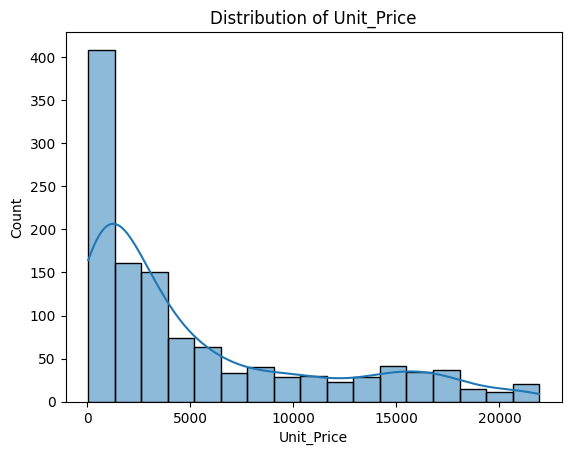

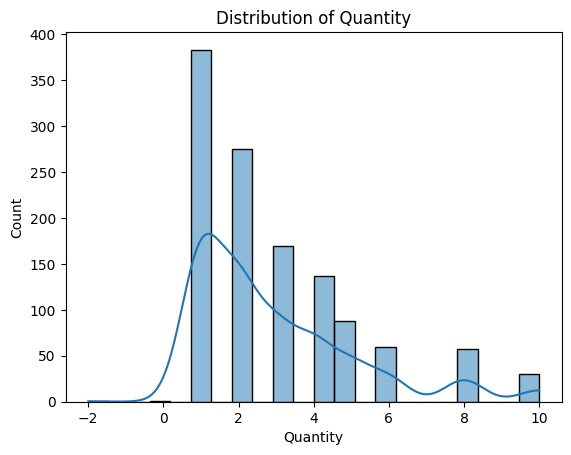

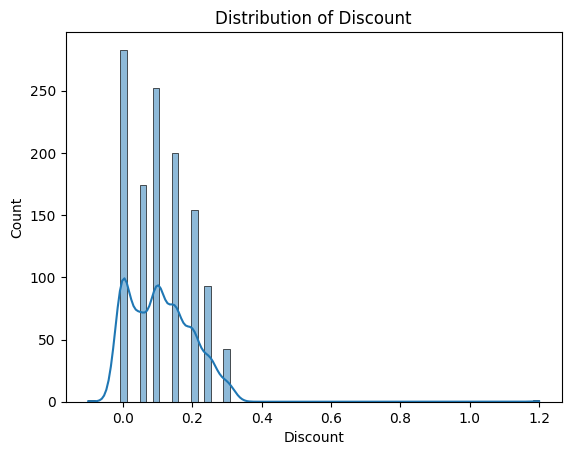

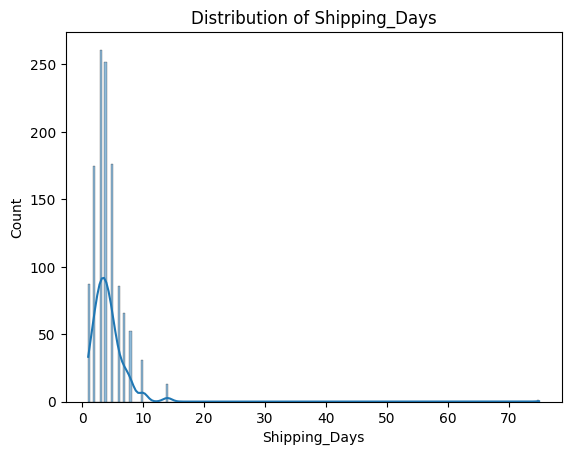

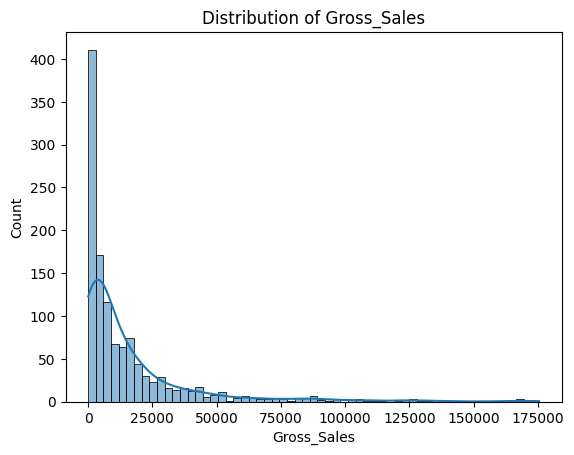

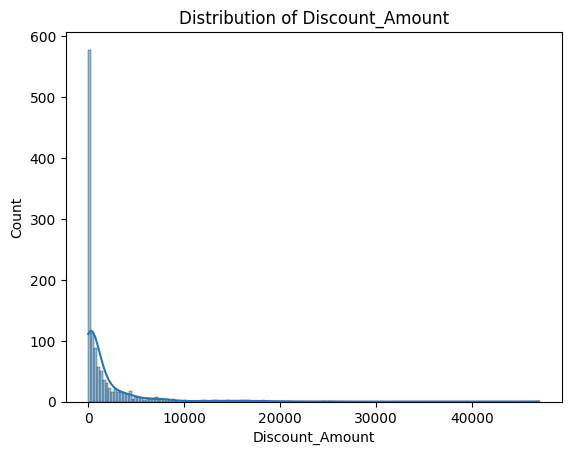

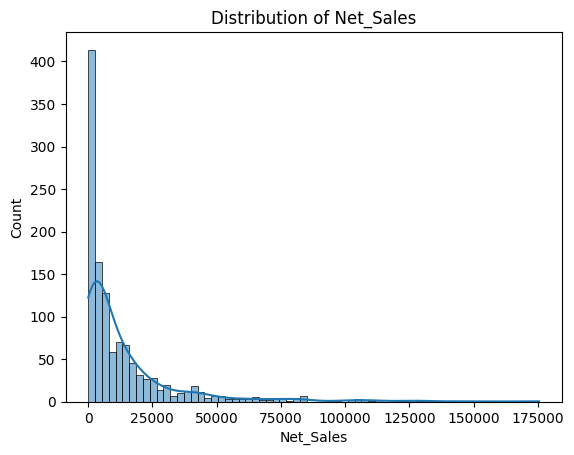

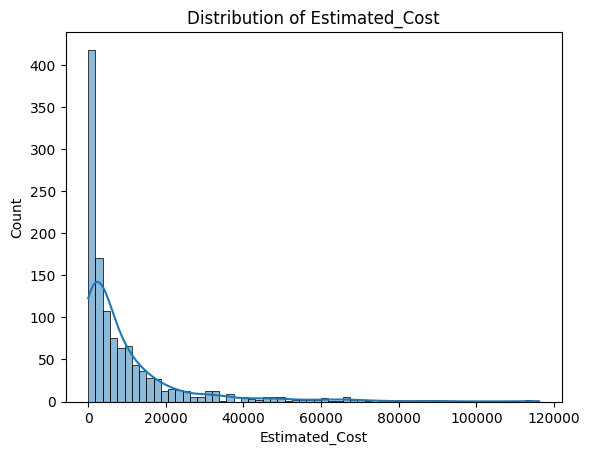

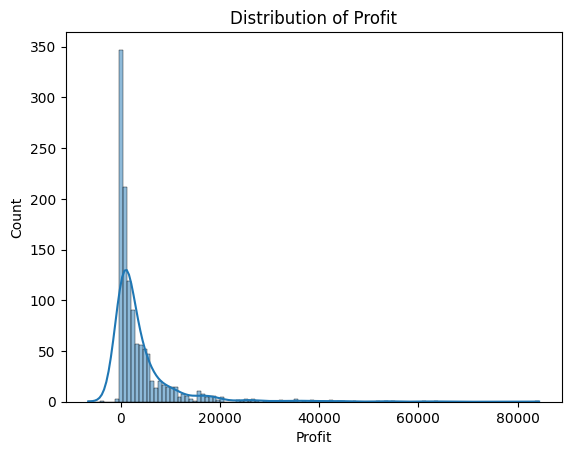

In [93]:
cols=["Unit_Price","Quantity","Discount","Shipping_Days","Gross_Sales","Discount_Amount","Net_Sales","Estimated_Cost","Profit"]
for col in cols:
    sns.histplot(x=col,data=df,kde=True)
    plt.title(f"Distribution of {col}")
    plt.show()

**Categorical Analysis Using Count Plots**

In [94]:
df.select_dtypes(include="object").columns

Index(['Order_ID', 'Customer_ID', 'Region', 'City', 'Customer_Segment',
       'Sales_Channel', 'Product_Category', 'Product_Name', 'Payment_Method',
       'Order_Status'],
      dtype='object')

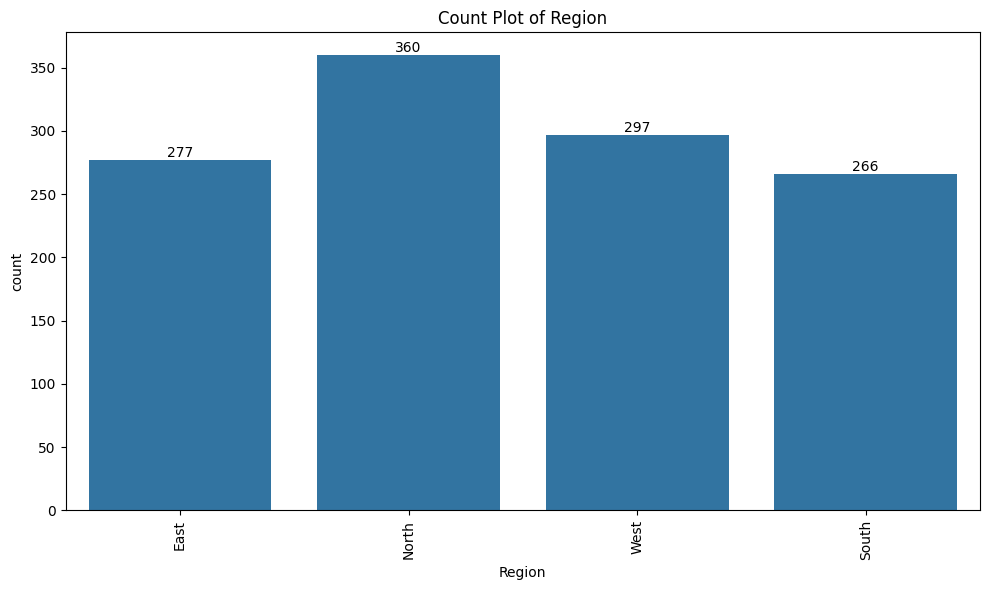

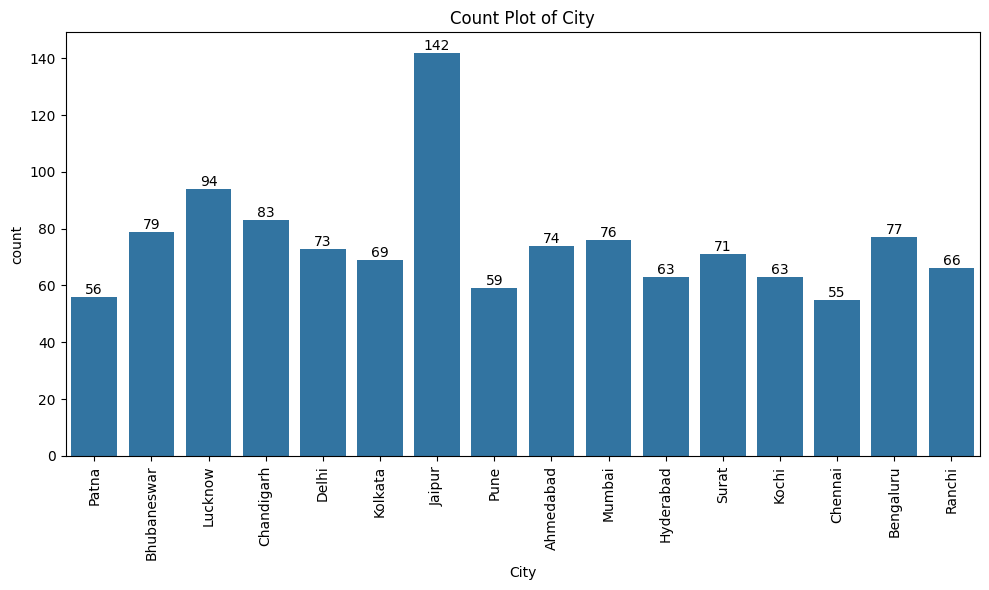

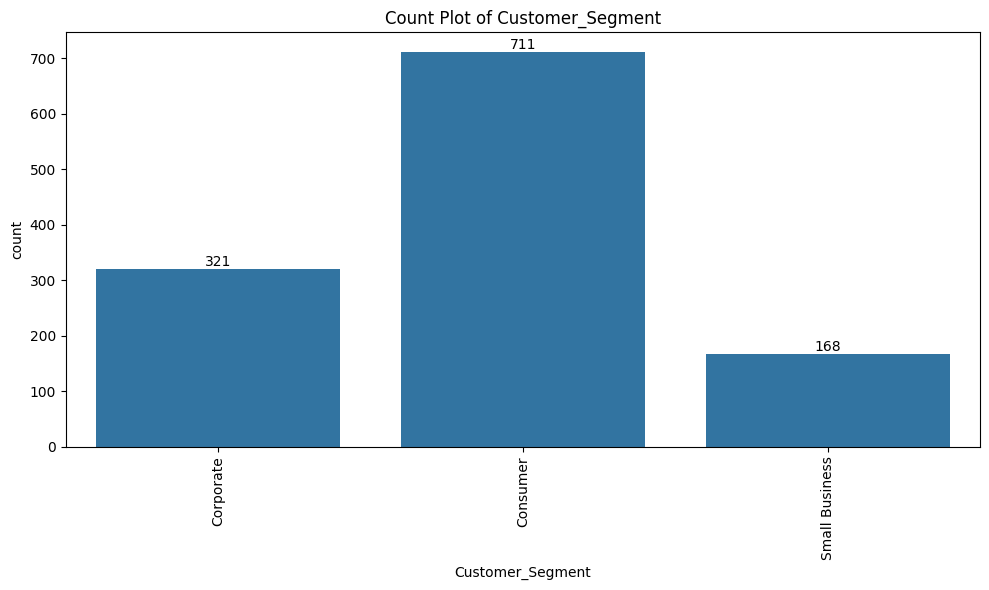

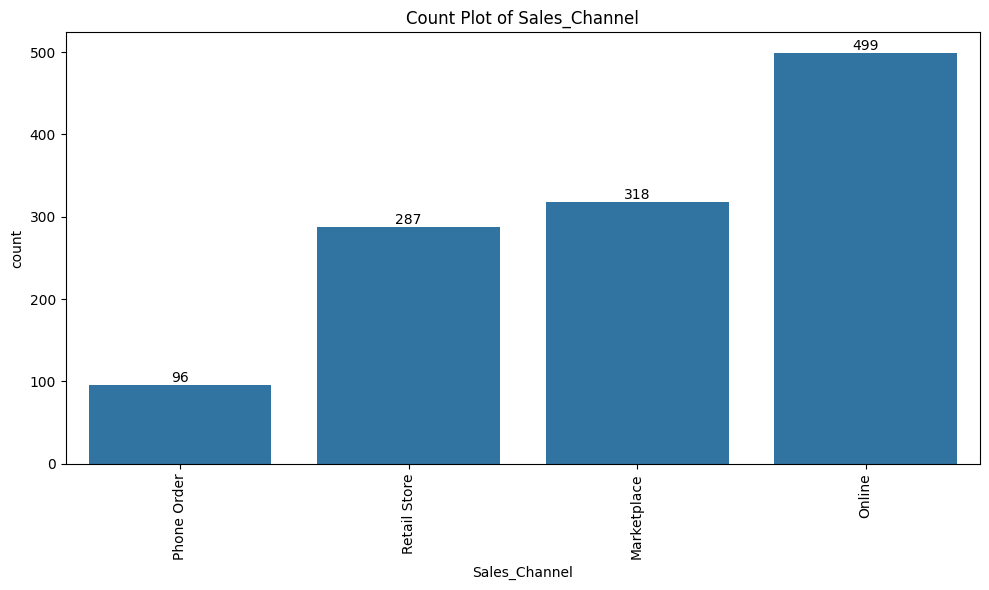

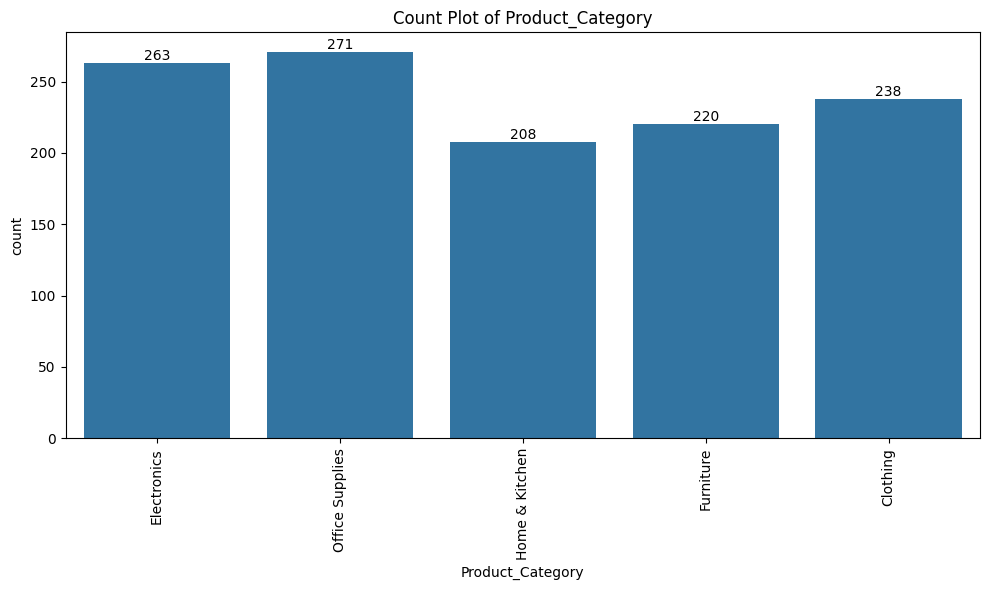

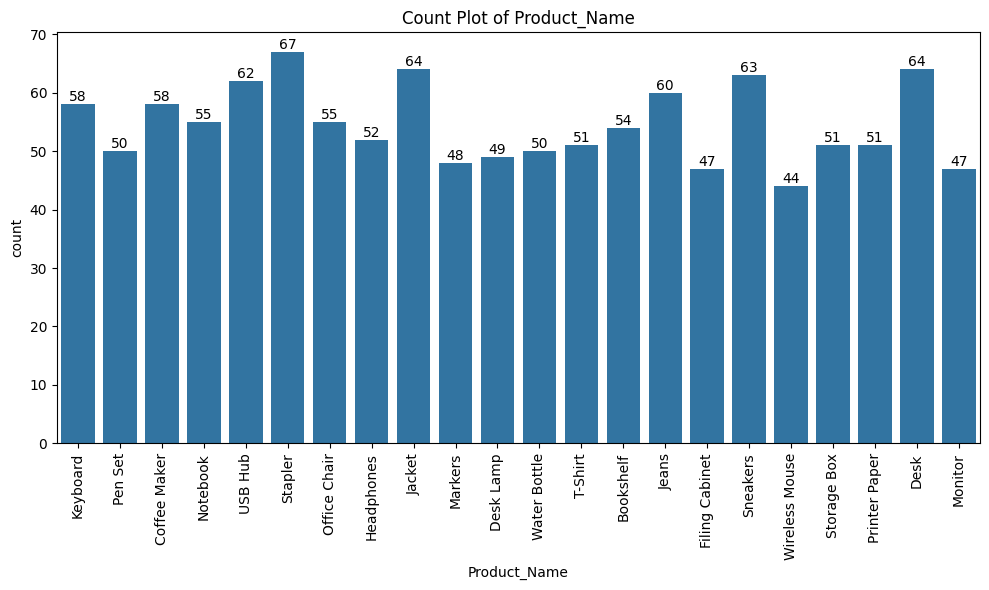

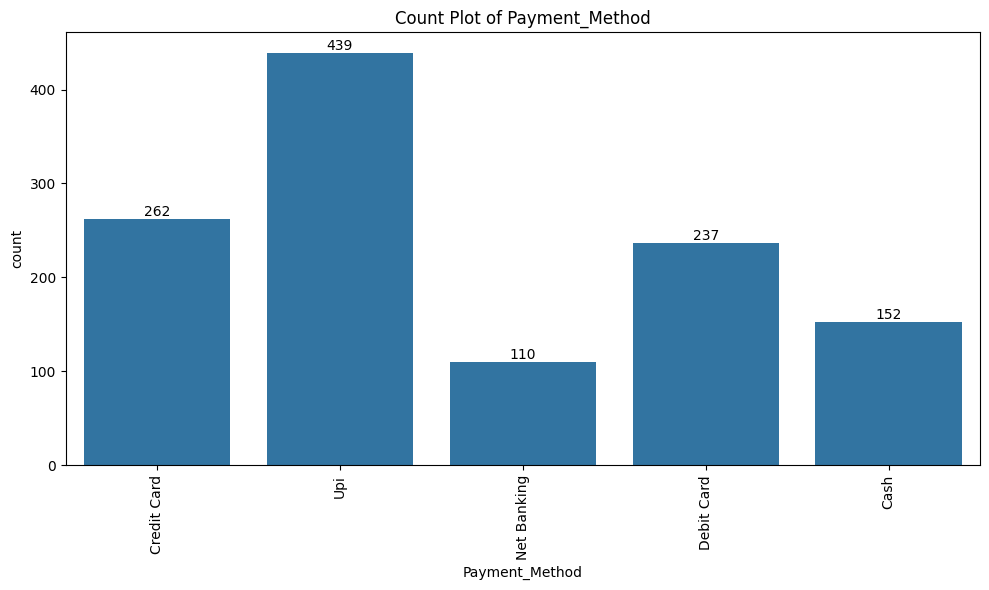

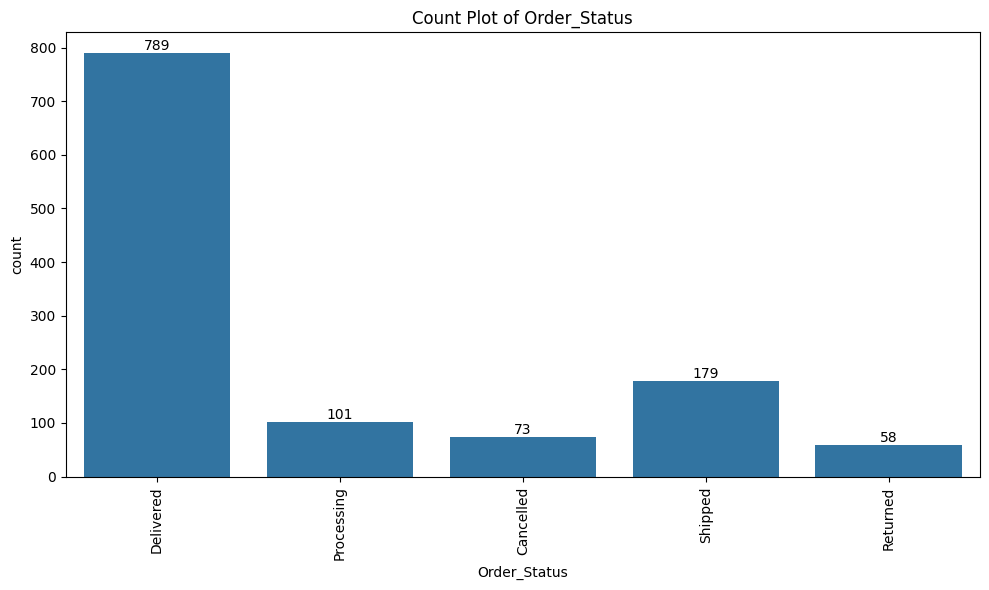

In [95]:
cols=['Region', 'City', 'Customer_Segment',
       'Sales_Channel', 'Product_Category', 'Product_Name', 'Payment_Method',
       'Order_Status']

for col in cols:
    plt.figure(figsize=(10,6))
    ax=sns.countplot(x=col,data=df)
    for container in ax.containers:
        ax.bar_label(container)

    plt.title(f"Count Plot of {col}")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

## Bivariate Analysis

In [96]:
print("Numerical Columns: \n")
numeric_cols=df.select_dtypes(include="number").columns
print(numeric_cols,"\n")
print("Categorical Columns: \n")
cat_cols=df.select_dtypes(include="object").columns
print(cat_cols)

Numerical Columns: 

Index(['Unit_Price', 'Quantity', 'Discount', 'Shipping_Days', 'Gross_Sales',
       'Discount_Amount', 'Net_Sales', 'Estimated_Cost', 'Profit'],
      dtype='object') 

Categorical Columns: 

Index(['Order_ID', 'Customer_ID', 'Region', 'City', 'Customer_Segment',
       'Sales_Channel', 'Product_Category', 'Product_Name', 'Payment_Method',
       'Order_Status'],
      dtype='object')


**1.Region Vs Net Sales**

- Which region generates the highest total net sales?

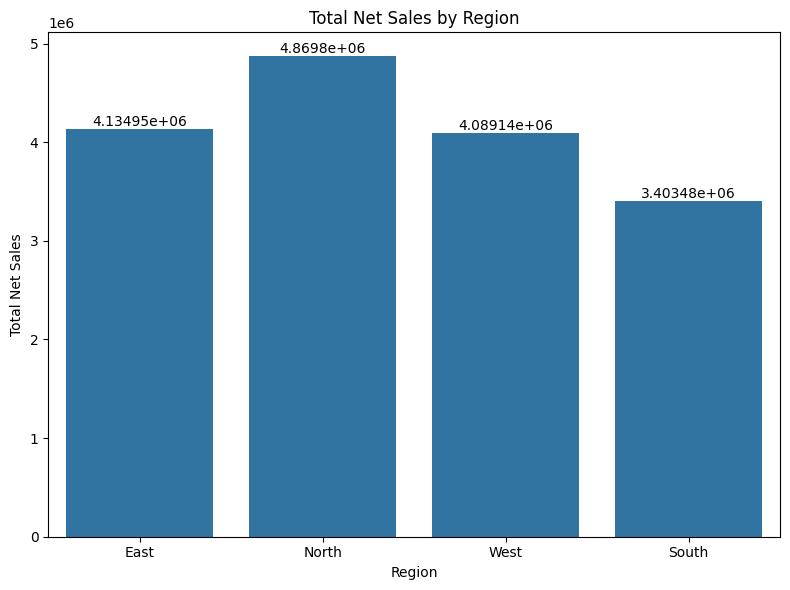

In [97]:
plt.figure(figsize=(8,6))
ax=sns.barplot(x="Region",y="Net_Sales",data=df,estimator="sum",errorbar=None)
for container in ax.containers:
    ax.bar_label(container)
plt.title("Total Net Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Net Sales")
plt.tight_layout()
plt.show()

**Product Category Vs Profit**

- Which product category generates highest total profit?

In [98]:
df.columns

Index(['Order_ID', 'Order_Date', 'Customer_ID', 'Region', 'City',
       'Customer_Segment', 'Sales_Channel', 'Product_Category', 'Product_Name',
       'Unit_Price', 'Quantity', 'Discount', 'Payment_Method', 'Order_Status',
       'Shipping_Days', 'Gross_Sales', 'Discount_Amount', 'Net_Sales',
       'Estimated_Cost', 'Profit'],
      dtype='object')

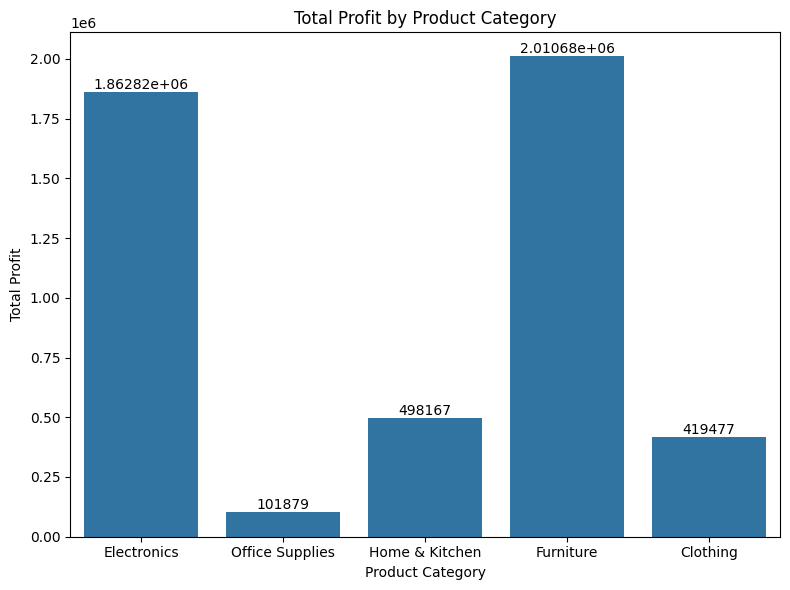

In [99]:
plt.figure(figsize=(8,6))
ax=sns.barplot(x="Product_Category",y="Profit",data=df,estimator="sum",errorbar=None)
for container in ax.containers:
    ax.bar_label(container)
plt.title("Total Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Profit")
plt.tight_layout()
plt.show()

**Customer Segment Vs Net Sales**

- Which customer segment contributes the most to net sales?

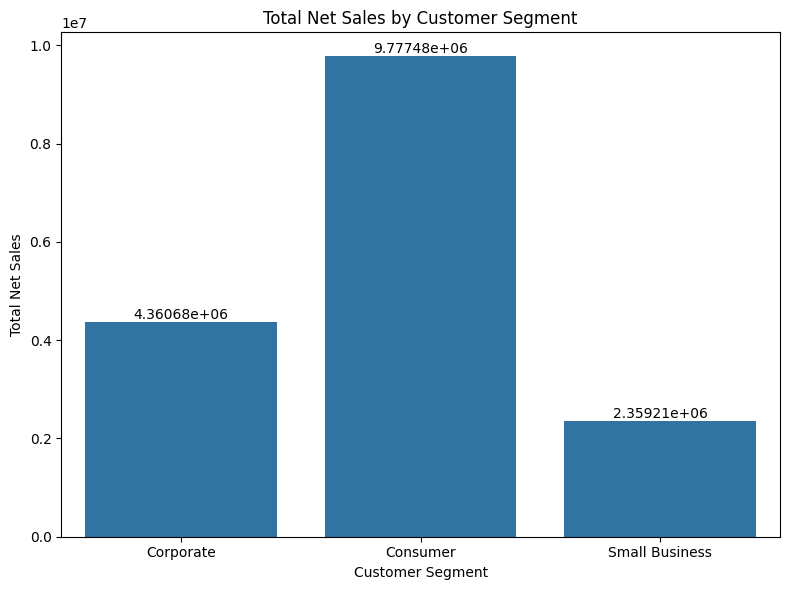

In [100]:
plt.figure(figsize=(8,6))
ax=sns.barplot(x="Customer_Segment",y="Net_Sales",data=df,estimator="sum",errorbar=None)
for container in ax.containers:
    ax.bar_label(container)
plt.title("Total Net Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Net Sales")
plt.tight_layout()
plt.show()

**Sales Channel Vs Order Status**

- How are order status distributed across sales channels?

In [101]:
pd.crosstab(df["Sales_Channel"],df["Order_Status"])

Order_Status,Cancelled,Delivered,Processing,Returned,Shipped
Sales_Channel,,,,,
Marketplace,18,206,24,23,47
Online,32,326,48,17,76
Phone Order,4,65,7,5,15
Retail Store,19,192,22,13,41


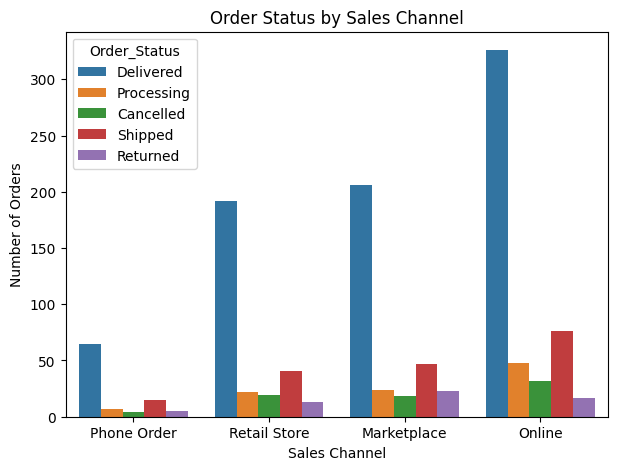

In [102]:
plt.figure(figsize=(7,5))
sns.countplot(x="Sales_Channel",hue="Order_Status",data=df)
plt.title("Order Status by Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Number of Orders")
plt.show()

## Time Series Analysis

In [103]:
df.head(2)

,Order_ID,Order_Date,Customer_ID,Region,City,Customer_Segment,Sales_Channel,Product_Category,Product_Name,Unit_Price,Quantity,Discount,Payment_Method,Order_Status,Shipping_Days,Gross_Sales,Discount_Amount,Net_Sales,Estimated_Cost,Profit
0,ORD-00047,2025-06-16,CUST-0199,East,Patna,Corporate,Phone Order,Electronics,Keyboard,5974.41,1,0.2,Credit Card,Delivered,3.0,5974.41,1194.88,4779.53,3021.95,1757.58
1,ORD-00291,2025-12-15,CUST-0089,East,Patna,Consumer,Retail Store,Office Supplies,Pen Set,475.48,2,0.0,Upi,Delivered,5.0,950.96,0.00,950.96,632.00,318.96


In [104]:
df.insert(2,"Order_Month",df["Order_Date"].dt.month_name())
df.head(1)

,Order_ID,Order_Date,Order_Month,Customer_ID,Region,City,Customer_Segment,Sales_Channel,Product_Category,Product_Name,...,Quantity,Discount,Payment_Method,Order_Status,Shipping_Days,Gross_Sales,Discount_Amount,Net_Sales,Estimated_Cost,Profit
0,ORD-00047,2025-06-16,June,CUST-0199,East,Patna,Corporate,Phone Order,Electronics,Keyboard,...,1,0.2,Credit Card,Delivered,3.0,5974.41,1194.88,4779.53,3021.95,1757.58


**Analyze Monthly Net Sales**

- How do net sales change from month to month?

In [107]:
monthly_sales=df.groupby("Order_Month")["Net_Sales"].sum().reindex(["January","February","March","April","May",
                                                                   "June","July","August","September","October","November","December"]).reset_index()
monthly_sales

,Order_Month,Net_Sales
0,January,1051716.42
1,February,1367907.56
2,March,845138.18
3,April,1712112.83
4,May,1397786.59
5,June,1419453.51
6,July,1237263.80
7,August,1619752.66
8,September,1564860.71
9,October,1373835.09


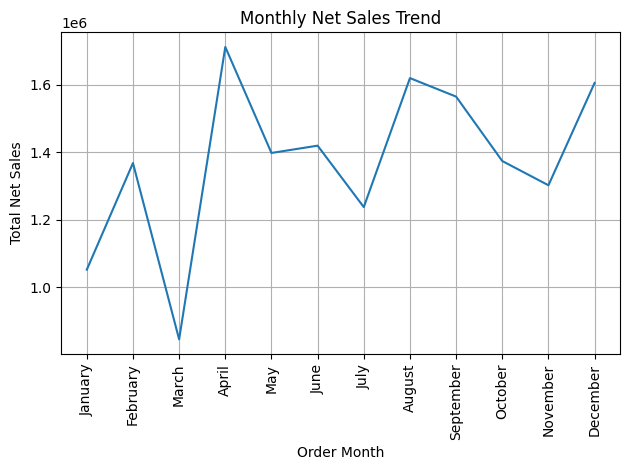

In [109]:
sns.lineplot(x="Order_Month",y="Net_Sales",data=monthly_sales,markers="o")
plt.xlabel("Order Month")
plt.ylabel("Total Net Sales")
plt.title("Monthly Net Sales Trend")
plt.grid(True)
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

**Calculate Monthly Profit**

- How does total profit change from month to month?

In [110]:
monthly_profit=df.groupby("Order_Month")["Profit"].sum().reindex(["January","February","March","April","May",
                                                                   "June","July","August","September","October","November","December"]).reset_index()
monthly_profit

,Order_Month,Profit
0,January,296047.06
1,February,394959.48
2,March,265876.54
3,April,578811.03
4,May,403595.07
5,June,392716.38
6,July,348425.40
7,August,503270.74
8,September,464753.60
9,October,405023.38


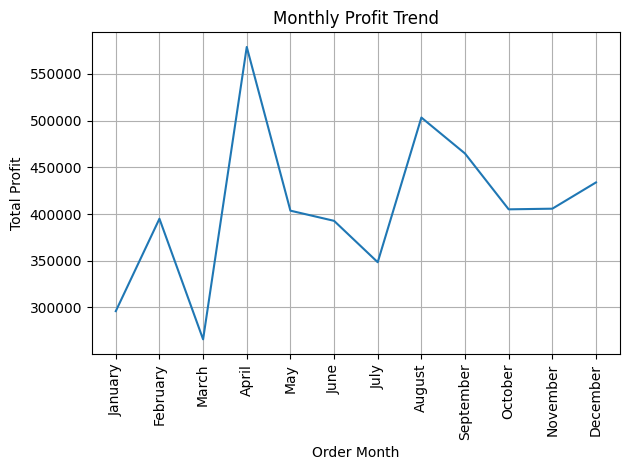

In [112]:
sns.lineplot(x="Order_Month",y="Profit",data=monthly_profit,markers="o")
plt.xlabel("Order Month")
plt.ylabel("Total Profit")
plt.title("Monthly Profit Trend")
plt.grid(True)
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## Business Questions and Insights

In [113]:
df.head(3)

,Order_ID,Order_Date,Order_Month,Customer_ID,Region,City,Customer_Segment,Sales_Channel,Product_Category,Product_Name,...,Quantity,Discount,Payment_Method,Order_Status,Shipping_Days,Gross_Sales,Discount_Amount,Net_Sales,Estimated_Cost,Profit
0,ORD-00047,2025-06-16,June,CUST-0199,East,Patna,Corporate,Phone Order,Electronics,Keyboard,...,1,0.20,Credit Card,Delivered,3.0,5974.41,1194.88,4779.53,3021.95,1757.58
1,ORD-00291,2025-12-15,December,CUST-0089,East,Patna,Consumer,Retail Store,Office Supplies,Pen Set,...,2,0.00,Upi,Delivered,5.0,950.96,0.00,950.96,632.00,318.96
2,ORD-00755,2025-03-19,March,CUST-0301,East,Bhubaneswar,Corporate,Marketplace,Home & Kitchen,Coffee Maker,...,1,0.25,Credit Card,Processing,7.0,4432.65,1108.16,3324.49,2941.65,382.84


**Which sales channel has the most delivered orders?**

In [115]:
df[df["Order_Status"]=="Delivered"]["Sales_Channel"].value_counts()

Sales_Channel
Online          326
Marketplace     206
Retail Store    192
Phone Order      65
Name: count, dtype: int64

**Which order status occurs most frequently?**

In [116]:
df["Order_Status"].value_counts()

Order_Status
Delivered     789
Shipped       179
Processing    101
Cancelled      73
Returned       58
Name: count, dtype: int64

**Which payment method is used most frequently?**

In [117]:
df["Payment_Method"].value_counts()

Payment_Method
Upi            439
Credit Card    262
Debit Card     237
Cash           152
Net Banking    110
Name: count, dtype: int64

**Which month has the highest net sales?**

In [120]:
df.groupby("Order_Month")["Net_Sales"].sum().reset_index().sort_values("Net_Sales",ascending=False)

,Order_Month,Net_Sales
0,April,1712112.83
1,August,1619752.66
2,December,1605517.30
11,September,1564860.71
6,June,1419453.51
8,May,1397786.59
10,October,1373835.09
3,February,1367907.56
9,November,1302029.00
5,July,1237263.80


**Which month has the highest profit?**

In [121]:
df.groupby("Order_Month")["Profit"].sum().reset_index().sort_values("Profit",ascending=False)

,Order_Month,Profit
0,April,578811.03
1,August,503270.74
11,September,464753.60
2,December,433825.70
9,November,405722.54
10,October,405023.38
8,May,403595.07
3,February,394959.48
6,June,392716.38
5,July,348425.40


# Business Insights and Key Findings

Based on the Exploratory Data Analysis, the following business insights were identified:

1. **Regional Sales Performance:** The North region generated the highest total net sales, approximately 4.87 million, among the four regions.

2. **Product Category Profitability:** Furniture generated the highest total profit, approximately 2.01 million, followed by Electronics.

3. **Customer Segment Analysis:** The Consumer segment contributed the highest net sales, approximately 9.78 million, followed by the Corporate segment.

4. **Sales Channel Performance:** Online was the leading sales channel for delivered orders, with 326 delivered orders.

5. **Order Status Analysis:** Delivered was the most frequent order status, with 789 orders.

6. **Payment Method Analysis:** UPI was the most frequently used payment method, with 439 orders.

7. **Monthly Net Sales:** April recorded the highest total net sales, approximately 1.71 million.

8. **Monthly Profit:** April also recorded the highest total profit, approximately 578,811.

9. **Monthly Trends:** The monthly analysis shows variations in net sales and profit throughout the year, with April performing particularly well.

# Conclusion

This project provided practical experience in performing Exploratory Data Analysis using Python. The dataset was inspected and cleaned by handling duplicate records, missing values, and inconsistent categorical values. Numerical data was also analyzed using descriptive statistics, box plots, and histograms.

Univariate, bivariate, and time-series analyses helped identify important patterns in regional sales, product profitability, customer segments, sales channels, payment methods, and monthly performance.

The analysis showed that the North region generated the highest net sales, Furniture generated the highest profit among product categories, and April recorded the highest monthly net sales and profit.

Overall, this project demonstrates how Python can be used to clean data, explore patterns, visualize business performance, and extract useful insights to support data-driven decision-making.